# Listening to a proton tunnel

A carbonic anhydrase proton, reduced to one coordinate, then listened to.
The numbers come from the same `src/` modules as the Streamlit app.
Cached Atlas results load with no API key. If `MOTH_API_KEY` is set, the Atlas sections submit fresh jobs and say so.


## 01 · The question

Enzymes move protons through places that look, classically, like walls. Carbonic anhydrase is the picture we keep in mind: a proton leaves zinc-bound water and ends up on the other side of the active site. In this model that trip is a particle in a double well. It does not have to climb the barrier. Part of its wave already sits on the far side.

Swap hydrogen for deuterium or tritium and the wall is the same, but the particle is heavier. The gap between the two lowest energies shrinks, and the time to appear in the other well grows. That ratio is the kinetic isotope effect. The crystal distance in PDB 1HED is only a landmark. It never enters the Hamiltonian.


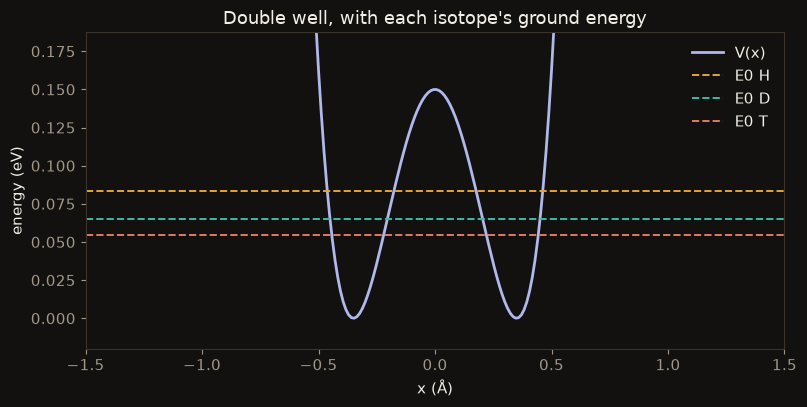

In [1]:
from pathlib import Path
import base64
import html
import json
import math
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, HTML, Video, display
from matplotlib.animation import FFMpegWriter

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.atlas_tomography import (
    SHOTS,
    bloch_length_shot_noise,
    circuit_qasm,
    population_errors,
    tomography_params,
)
from src.hamiltonian import ANGSTROM_M, JOULE_PER_EV
from src.moth_sonification import tunneling_beat
from src.quantum_sim import evolve_exact

BARRIER_EV = 0.15
HALF_WIDTH_A = 0.35
COLORS = {"H": "#e4a23a", "D": "#3cbaa6", "T": "#e07a5f"}

plt.rcParams.update({
    "figure.facecolor": "#12110f",
    "axes.facecolor": "#12110f",
    "axes.edgecolor": "#3a342c",
    "axes.labelcolor": "#f3eee6",
    "xtick.color": "#a39888",
    "ytick.color": "#a39888",
    "text.color": "#f3eee6",
    "font.size": 11,
})

physics = {}
shared_model = None
for mass in ("H", "D", "T"):
    model, evolution = evolve_exact(
        barrier_ev=BARRIER_EV,
        asymmetry_ev=0.0,
        well_half_width_angstrom=HALF_WIDTH_A,
        mass=mass,
        n_periods=1.0,
        n_steps=1,
        keep_states=False,
    )
    energies = evolution.energies_j
    splitting = float(energies[1] - energies[0])
    physics[mass] = {
        "model": model,
        "e0_ev": float(energies[0] / JOULE_PER_EV),
        "splitting_ev": float(evolution.splitting_ev),
        "period_s": float(evolution.tunneling_period_s),
        "ratio": float(energies[2] - energies[1]) / splitting,
    }
    if shared_model is None:
        shared_model = model

x_a = shared_model.x_m / ANGSTROM_M
v_ev = shared_model.v_joule / JOULE_PER_EV

fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.plot(x_a, v_ev, color="#b0b8ec", lw=2.0, label="V(x)")
for mass, row in physics.items():
    ax.axhline(row["e0_ev"], color=COLORS[mass], lw=1.4, ls="--", label=f"E0 {mass}")
ax.set_xlim(float(x_a[0]), float(x_a[-1]))
ax.set_ylim(-0.02, float(np.max(v_ev[np.abs(x_a) < 0.2])) * 1.25)
ax.set_xlabel("x (Å)")
ax.set_ylabel("energy (eV)")
ax.set_title("Double well, with each isotope's ground energy")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()


## 02 · The physics

The grid is 256 sites, from −1.5 Å to 1.5 Å, which is an 8-qubit register. The potential is V(x) = E_b (1 − (x/a)²)² with E_b = 0.15 eV and a = 0.35 Å. Hydrogen, deuterium, and tritium share that wall. Only the mass in the kinetic term changes.

The reference clock is a matrix exponential of this Hamiltonian. ΔE is the gap E1 − E0. The tunneling period is h/ΔE, the time for a round trip between the wells. A one-qubit picture is fair when the next gap, E2 − E1, is more than five times ΔE. The lines below are that check.


In [2]:
print(f"Well: E_b = {BARRIER_EV} eV, a = {HALF_WIDTH_A} Å, λ = 0")
for mass, row in physics.items():
    mev = row["splitting_ev"] * 1e3
    femtoseconds = row["period_s"] * 1e15
    print(
        f"{mass}  ΔE = {mev:.3f} meV   "
        f"T_tun = {femtoseconds:.2f} fs   "
        f"(E2 − E1) / ΔE = {row['ratio']:.3f}"
    )
    if row["ratio"] <= 5.0:
        raise RuntimeError(f"{mass} is not safely inside the two-level window.")

kie = physics["H"]["splitting_ev"] / physics["D"]["splitting_ev"]
print(f"KIE  ΔE(H) / ΔE(D) = {kie:.3f}")
print(
    "Heavier nuclei have the smaller splitting, so deuterium and tritium "
    "take longer to reach the other well."
)


Well: E_b = 0.15 eV, a = 0.35 Å, λ = 0
H  ΔE = 14.239 meV   T_tun = 290.44 fs   (E2 − E1) / ΔE = 8.007
D  ΔE = 2.697 meV   T_tun = 1533.33 fs   (E2 − E1) / ΔE = 33.538
T  ΔE = 0.736 meV   T_tun = 5617.83 fs   (E2 − E1) / ΔE = 113.146
KIE  ΔE(H) / ΔE(D) = 5.279
Heavier nuclei have the smaller splitting, so deuterium and tritium take longer to reach the other well.


## 03 · Atlas, step 1 (Tomography)

The two-level reduction is one qubit. |0⟩ is the donor well and |1⟩ is the acceptor well. At time t along one tunneling period the circuit is `rx(2π t / T)` on |0⟩. OpenQASM 2 is what `tomography-api-v2` asks for.

The provider name is `aer` and the backend is `automatic`. That is a simulator. Each of X, Y, and Z is measured with 4096 shots. Before any job, the same circuits are checked against the exact grid populations. The notebook then either loads `src/atlas_bank.json` or, when `MOTH_API_KEY` is set, submits the 24 jobs and writes that file again.


path: cache — MOTH_API_KEY is not set, loading src/atlas_bank.json


local check before trusting the qubit: max |P_rx − P_exact| = 0.0185

OpenQASM 2 at t/T = 0.25
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
rx(pi/2) q[0];
request JSON
{
  "circuit_qasm": "OPENQASM 2.0;\ninclude \"qelib1.inc\";\nqreg q[1];\nrx(pi/2) q[0];",
  "single_tomography": true,
  "double_tomography": false,
  "mutual_information": false,
  "classical_mutual_information": false,
  "shots": 4096,
  "provider_name": "aer",
  "backend_name": "automatic",
  "qubit_list": [
    0
  ]
}

aer/automatic · simulator · 4096 shots · tomography-api-v2
aer simulator, 4096 shots, two-level model.
job ids:
86ca6264-75fb-465c-9340-40608f455667
f7b0c643-471d-48d8-9e11-35aab6890640
1e1f8c75-805c-4136-9d48-a3e8076bd91d
332f4da2-5be6-4331-9321-f5f52af74d07
5eba3feb-3bf9-4abd-b016-3948f0c5faef
dff27734-1b5a-4102-8e2b-936d0082a68e
3899defe-3d2f-417d-ab78-13892240cf36
932a4227-2872-4ec7-bbc3-2bed2e20f170
b18ddbde-1dc3-4f28-90af-f655a3d30931
27b0892b-be77-4f3c-8e89-046bd646aa93
44280f4f-0160-4c8f-9e0

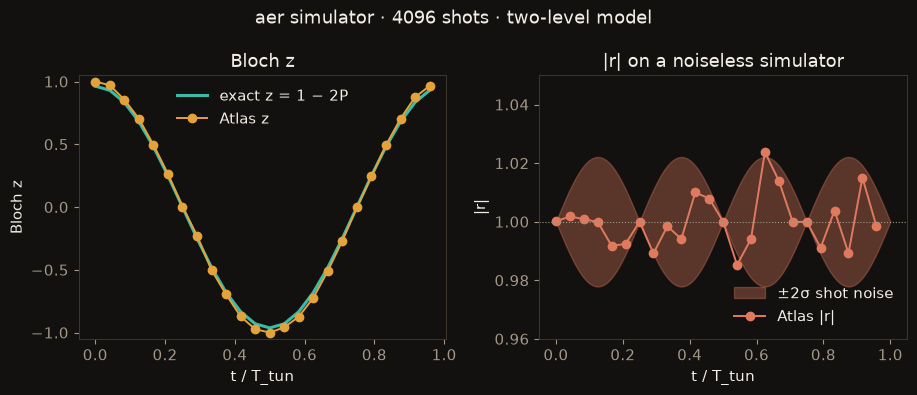

On a noiseless simulator, deviations from |r| = 1 are sampling noise, not decoherence.


In [3]:
key = os.environ.get("MOTH_API_KEY", "").strip()
bank_path = ROOT / "src" / "atlas_bank.json"
if key:
    print("path: live — MOTH_API_KEY is set, submitting tomography-api-v2")
    from src.atlas_tomography import write_atlas_bank
    write_atlas_bank(bank_path)
    atlas_path_taken = "live"
else:
    print("path: cache — MOTH_API_KEY is not set, loading src/atlas_bank.json")
    if not bank_path.exists():
        raise FileNotFoundError("Cached atlas_bank.json is missing and no API key is set.")
    atlas_path_taken = "cache"

worst, _exact, _predicted = population_errors()
print(f"local check before trusting the qubit: max |P_rx − P_exact| = {worst:.4f}")
if worst >= 0.02:
    raise RuntimeError("The RX circuits miss the exact acceptor population.")

sample_time = 0.25
qasm = circuit_qasm(sample_time)
request = tomography_params(qasm, SHOTS)
print(f"\nOpenQASM 2 at t/T = {sample_time}")
print(qasm)
print("request JSON")
print(json.dumps(request, indent=2))

bank = json.loads(bank_path.read_text(encoding="utf-8"))
print(
    f"\n{bank['provider']}/{bank['backend']} · {bank['execution']} · "
    f"{bank['shots']} shots · {bank['engine']}"
)
print("aer simulator, 4096 shots, two-level model.")
print("job ids:")
for job_id in bank["job_ids"]:
    print(job_id)

times = np.array([point["t_over_period"] for point in bank["points"]], dtype=float)
z_atlas = np.array([point["z"] for point in bank["points"]], dtype=float)
ideal_p = np.array([point["ideal_acceptor"] for point in bank["points"]], dtype=float)
z_exact = 1.0 - 2.0 * ideal_p
length = np.array([point["bloch_length"] for point in bank["points"]], dtype=float)
shots = int(bank["shots"])
grid = np.linspace(0.0, 1.0, 361)
half = 2.0 * np.array([bloch_length_shot_noise(float(t), shots) for t in grid])

fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.0))
axes[0].plot(times, z_exact, color="#3cbaa6", lw=2.2, label="exact z = 1 − 2P")
axes[0].plot(times, z_atlas, color="#e4a23a", marker="o", lw=1.4, label="Atlas z")
axes[0].set_ylabel("Bloch z")
axes[0].set_ylim(-1.05, 1.05)
axes[0].set_title("Bloch z")
axes[0].legend(frameon=False)

axes[1].fill_between(grid, 1.0 - half, 1.0 + half, color="#e07a5f", alpha=0.35, label="±2σ shot noise")
axes[1].plot(times, length, color="#e07a5f", marker="o", lw=1.4, label="Atlas |r|")
axes[1].axhline(1.0, color="#a39888", lw=0.8, ls=":")
axes[1].set_ylabel("|r|")
axes[1].set_ylim(0.96, 1.05)
axes[1].set_title("|r| on a noiseless simulator")
axes[1].legend(frameon=False, loc="lower right")
for axis in axes:
    axis.set_xlabel("t / T_tun")
fig.suptitle("aer simulator · 4096 shots · two-level model", color="#f3eee6")
fig.tight_layout()
plt.show()
print(
    "On a noiseless simulator, deviations from |r| = 1 are sampling noise, not decoherence."
)


## 04 · Atlas, step 2 (Teleblur)

The donor and acceptor pictures are ordinary PNGs. The Assets route gives back a presigned URL. The bytes go there with the headers from that response, not with the API key. `telablur-v1` then takes the two asset ids.

`strength` is the teleportation effect, from 0 to 1. A selector qubit rotates so the two images meet in amplitude. The schema does not call that a linear blend of the color channels. Output alpha, when there is any, is alpha1·(1−strength) + alpha2·strength. The third file slot is an optional mask. It was left empty, so the whole RGB frame is teleblurred.

The row below is the donor, one returned frame, and the acceptor.


path: cache — MOTH_API_KEY is not set, loading atlas_outputs/
asset upload body for donor.png
{
  "filename": "donor.png",
  "content_type": "image/png",
  "size_bytes": 8062
}

telablur-v1 request
{
  "input_files": {
    "image1": "<asset id returned for donor.png>",
    "image2": "<asset id returned for acceptor.png>"
  },
  "params": {
    "strength": 0.5,
    "size": 128,
    "downscale": true,
    "direction": "full"
  }
}
strength is the teleportation-effect parameter (0 to 1): a selector-qubit rotation interpolates the images at the amplitude level. Output alpha is alpha1*(1-strength)+alpha2*strength. The schema does not define strength as a linear RGB morph fraction. The optional mask slot was not sent.
cached frame job 68c87e41-d913-4f29-866f-129556c5ab9f · engine telablur-v1


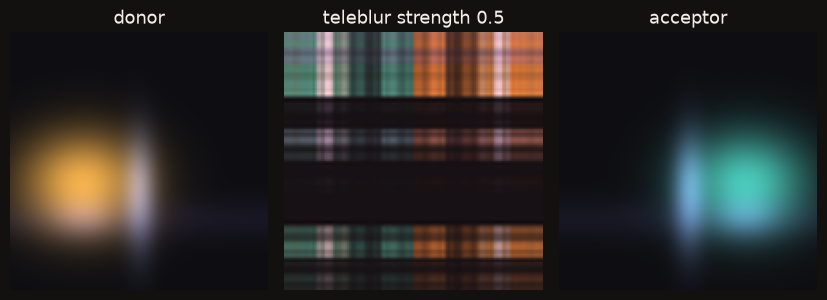

In [4]:
output_dir = ROOT / "atlas_outputs"
donor_path = ROOT / "atlas_inputs" / "donor.png"
acceptor_path = ROOT / "atlas_inputs" / "acceptor.png"
if key:
    print("path: live — MOTH_API_KEY is set, uploading images and submitting telablur-v1")
    from src.atlas_teleblur import write_frames
    write_frames()
    teleblur_path_taken = "live"
else:
    print("path: cache — MOTH_API_KEY is not set, loading atlas_outputs/")
    if not donor_path.exists() or not any(output_dir.glob("frame_*.png")):
        raise FileNotFoundError("Cached Teleblur frames are missing and no API key is set.")
    teleblur_path_taken = "cache"

donor_bytes = donor_path.stat().st_size
print("asset upload body for donor.png")
print(json.dumps({
    "filename": donor_path.name,
    "content_type": "image/png",
    "size_bytes": donor_bytes,
}, indent=2))

mid = json.loads((output_dir / "frame_05.json").read_text(encoding="utf-8"))
print("\ntelablur-v1 request")
print(json.dumps({
    "input_files": {
        "image1": "<asset id returned for donor.png>",
        "image2": "<asset id returned for acceptor.png>",
    },
    "params": mid["params"],
}, indent=2))
print(mid["strength_note"])
print(f"cached frame job {mid['job_id']} · engine {mid['engine']}")

frame_path = output_dir / "frame_05.png"
images = [
    ("donor", plt.imread(donor_path)),
    (f"teleblur strength {mid['params']['strength']}", plt.imread(frame_path)),
    ("acceptor", plt.imread(acceptor_path)),
]
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.1))
for axis, (label, image) in zip(axes, images):
    axis.imshow(image)
    axis.set_title(label)
    axis.axis("off")
fig.tight_layout()
plt.show()


## 05 · Generating media

Each isotope gets a stereo clip. Two tones sit a few hertz apart. That beat follows log10(ΔE), so hydrogen chatters faster than tritium. The left channel follows the donor population and the right channel follows the acceptor. It is a listening model, not a spectrum of the Hamiltonian.

Then a 10-second movie of the same slowed clock. One hydrogen period is 1.6 seconds on screen. Deuterium and tritium keep their real period ratios, so in the same ten seconds they travel less far.


In [5]:
movie = json.loads((ROOT / "src" / "experience_data.json").read_text(encoding="utf-8"))
media_dir = ROOT / "notebooks" / "media"
media_dir.mkdir(parents=True, exist_ok=True)
x_movie = np.asarray(movie["x"], dtype=float)
v_movie = np.asarray(movie["v"], dtype=float)
print(movie["time_scale_label"])

for mass in ("H", "D", "T"):
    isotope = movie["isotopes"][mass]
    clip = tunneling_beat(
        np.asarray(isotope["donor"], dtype=float),
        np.asarray(isotope["acceptor"], dtype=float),
        splitting_ev=float(isotope["deltaE_meV"]) / 1e3,
    )
    print(f"{mass}: {clip.note}")
    display(Audio(data=clip.wav_bytes))

def render_tunnel_video(mass: str, destination: Path, seconds: float = 10.0, fps: int = 10) -> None:
    isotope = movie["isotopes"][mass]
    density = np.asarray(isotope["density"], dtype=float)
    e0 = float(isotope["e0_ev"])
    span = float(isotope["screen_period_s"]) * int(movie["periods"])
    crest = float(density.max())
    amp = 0.055
    fig, ax = plt.subplots(figsize=(7.2, 3.5))
    ax.plot(x_movie, v_movie, color="#b0b8ec", lw=1.3)
    ax.axhline(e0, color=COLORS[mass], lw=1.0, ls="--")
    wave_line, = ax.plot(x_movie, np.full_like(x_movie, e0), color=COLORS[mass], lw=2.0)
    poly = ax.fill_between(x_movie, e0, e0, color=COLORS[mass], alpha=0.8)
    ax.set_xlim(float(x_movie[0]), float(x_movie[-1]))
    ax.set_ylim(-0.02, max(0.22, e0 + amp + 0.04))
    ax.set_xlabel("x (Å)")
    ax.set_ylabel("energy (eV)")
    title = ax.set_title(mass)
    fig.tight_layout()
    writer = FFMpegWriter(fps=fps, bitrate=1200)
    n_frames = int(seconds * fps)
    n_density = len(density)
    with writer.saving(fig, str(destination), dpi=90):
        for step in range(n_frames):
            clock = step / fps
            pos = (clock % span) / span * (n_density - 1)
            left = int(math.floor(pos))
            right = min(n_density - 1, left + 1)
            local = pos - left
            sample = density[left] * (1.0 - local) + density[right] * local
            crest_y = e0 + (sample / crest) * amp
            wave_line.set_ydata(crest_y)
            poly.remove()
            poly = ax.fill_between(x_movie, e0, crest_y, color=COLORS[mass], alpha=0.8)
            title.set_text(f"{mass} · {clock:.1f} s of slowed time")
            writer.grab_frame()
    plt.close(fig)

for mass in ("H", "D", "T"):
    video_path = media_dir / f"tunnel_{mass.lower()}.mp4"
    render_tunnel_video(mass, video_path)
    print(f"wrote {video_path.relative_to(ROOT)}")
    display(Video(str(video_path), embed=True, html_attributes="controls"))


time slowed ~10^13×
H: Artistic mapping. Tones at 220.0 Hz and 229.57 Hz (beat 9.57 Hz from log10(ΔE)). Left follows the donor, right the acceptor.


D: Artistic mapping. Tones at 220.0 Hz and 227.49 Hz (beat 7.49 Hz from log10(ΔE)). Left follows the donor, right the acceptor.


T: Artistic mapping. Tones at 220.0 Hz and 225.87 Hz (beat 5.87 Hz from log10(ΔE)). Left follows the donor, right the acceptor.


wrote notebooks/media/tunnel_h.mp4


wrote notebooks/media/tunnel_d.mp4


wrote notebooks/media/tunnel_t.mp4


## 06 · The application

This is the Experience view from the app, dropped into the notebook. Tap the landscape and the collapse is drawn from the Atlas bank. The Bloch sphere in the corner is the same aer run. If you just watched the intro above, you will see it once more here, for six seconds, before Begin wakes up.



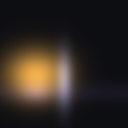
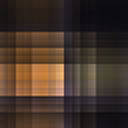
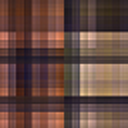
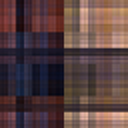
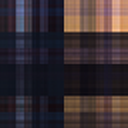
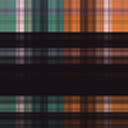
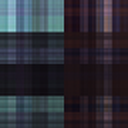
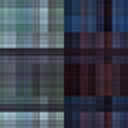
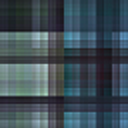
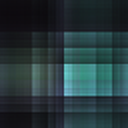
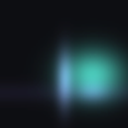

In [6]:
template = (ROOT / "src" / "experience.html").read_text(encoding="utf-8")
atlas_text = bank_path.read_text(encoding="utf-8") if bank_path.exists() else "null"
local_bank = (ROOT / "src" / "bank.json").read_text(encoding="utf-8")
frames = sorted(output_dir.glob("frame_*.png"))
if frames:
    intro_urls = []
    for path in frames:
        encoded = base64.b64encode(path.read_bytes()).decode("ascii")
        intro_urls.append(f"data:image/png;base64,{encoded}")
    intro_json = json.dumps(intro_urls)
else:
    intro_json = "null"
experience = template
for token, value in (
    ("__EXPERIENCE_DATA__", (ROOT / "src" / "experience_data.json").read_text(encoding="utf-8")),
    ("__BANK_DATA__", local_bank),
    ("__ATLAS_BANK__", atlas_text),
    ("__INTRO_FRAMES__", intro_json),
):
    if token not in experience:
        raise RuntimeError(f"experience.html is missing {token}")
    experience = experience.replace(token, value, 1)
srcdoc = html.escape(experience, quote=True)
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    display(HTML(
        '<iframe srcdoc="' + srcdoc + '" '
        'style="width:100%;height:760px;border:0;border-radius:12px;background:#0e0e10"></iframe>'
    ))


## 07 · What this is and isn't

This is a simulator. `aer` / `automatic` is not a quantum processor, and nothing on the page should be read as hardware. With 4096 shots on a noiseless machine, `|r|` wanders off 1 because of sampling. That is shot noise. The word coherence stays reserved for a real QPU.

Time on screen is slowed by about 10¹³ so a person can watch a period that, in the laboratory, is a fraction of a picosecond. The ratios between H, D, and T are the physical ones. The stretch factor is not.

The stereo tones are an artistic map. Pitch is chosen. The beat follows the logarithm of ΔE. Left and right follow the two wells. None of that is the spectrum of H.

The enzyme is context. PDB 1HED can put a zinc–water distance on the Lab page, and that distance is not fed to V(x). The barrier height and the well spacing are model choices. The kinetic isotope effect here is ΔE(H)/ΔE(D) for this Hamiltonian, not a measured enzyme rate.

The one-qubit circuits are a two-level reduction of the 256-site grid. Section 02 checks that the next gap is wide enough, and section 03 checks that `rx(2π t / T)` reproduces the donor and acceptor populations before Atlas is asked to measure them.


## Credits

Moth engines used for the Atlas sections:

- `tomography-api-v2` measures the one-qubit tunneling clock.
- `telablur-v1` morphs the donor picture toward the acceptor. Images arrive through the Assets presign flow.

The job ids from this run are printed below. A cache run repeats the ids already saved on disk. A live run replaces them with the jobs just submitted.


In [7]:
print(f"tomography path: {atlas_path_taken}")
print(f"engine: {bank['engine']} · {bank['provider']}/{bank['backend']} · {bank['execution']}")
for job_id in bank["job_ids"]:
    print(f"  tomography {job_id}")
print(f"teleblur path: {teleblur_path_taken}")
for sidecar_path in sorted(output_dir.glob("frame_*.json")):
    sidecar = json.loads(sidecar_path.read_text(encoding="utf-8"))
    strength = sidecar["params"]["strength"]
    print(f"  {sidecar['engine']} strength {strength:.1f} {sidecar['job_id']}")


tomography path: cache
engine: tomography-api-v2 · aer/automatic · simulator
  tomography 86ca6264-75fb-465c-9340-40608f455667
  tomography f7b0c643-471d-48d8-9e11-35aab6890640
  tomography 1e1f8c75-805c-4136-9d48-a3e8076bd91d
  tomography 332f4da2-5be6-4331-9321-f5f52af74d07
  tomography 5eba3feb-3bf9-4abd-b016-3948f0c5faef
  tomography dff27734-1b5a-4102-8e2b-936d0082a68e
  tomography 3899defe-3d2f-417d-ab78-13892240cf36
  tomography 932a4227-2872-4ec7-bbc3-2bed2e20f170
  tomography b18ddbde-1dc3-4f28-90af-f655a3d30931
  tomography 27b0892b-be77-4f3c-8e89-046bd646aa93
  tomography 44280f4f-0160-4c8f-9e04-3111c1e50a82
  tomography 98658466-298a-4c1c-9215-c481ead651d2
  tomography 6ea83342-a74f-4ee6-957c-01f7bdf177bc
  tomography b63752a4-d4bb-4789-9fb5-8ef800a77414
  tomography ff34084a-a5ea-43b3-aace-f40cfe8d79a1
  tomography 529dfa64-2a80-4c5f-a952-1ee289e43f3e
  tomography 660a1729-94ea-40a1-8e88-4986cf8f4456
  tomography 3cb5a9bd-0f73-4ed6-924d-3885eae43786
  tomography 7f71b375-3